# E-Commerce Customer Segmentation CASE STUDY


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


In [ ]:

np.random.seed(42)
n = 300
df = pd.DataFrame({
    'CustomerID': np.arange(1, n + 1),
    'Recency': np.random.randint(1, 366, n),
    'Frequency': np.random.randint(1, 31, n),
    'Monetary': np.random.randint(100, 10001, n)
})
df.to_csv('rfm_customers.csv', index=False)


In [ ]:
print('First five rows:\n', df.head())
print('\nMissing values:\n', df.isnull().sum())
X = df[['Recency', 'Frequency', 'Monetary']]
X_scaled = StandardScaler().fit_transform(X)


First five rows:
    CustomerID  Recency  Frequency  Monetary
0           1      103         14      4074
1           2      349         21      3367
2           3      271         16       925
3           4      107         20      7768
4           5       72         24      5845

Missing values:
 CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


In [ ]:

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
print('\nK-Means silhouette:', round(silhouette_score(X_scaled, df['KMeans_Cluster']), 3))



K-Means silhouette: 0.279


In [ ]:

dbscan = DBSCAN(eps=0.6, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)
db_labels = df['DBSCAN_Cluster'].to_numpy()
non_noise = db_labels != -1
if len(np.unique(db_labels[non_noise])) >= 2:
    print('DBSCAN silhouette (excluding noise):', round(silhouette_score(X_scaled[non_noise], db_labels[non_noise]), 3))
else:
    print('DBSCAN silhouette: not defined (fewer than two non-noise clusters)')
print('DBSCAN clusters:', len(set(db_labels) - {-1}), '| Noise customers:', sum(db_labels == -1))


DBSCAN silhouette (excluding noise): 0.195
DBSCAN clusters: 2 | Noise customers: 28


In [ ]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('PCA variance retained:', round(sum(pca.explained_variance_ratio_) * 100, 2), '%')


PCA variance retained: 71.8 %


In [ ]:

X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)


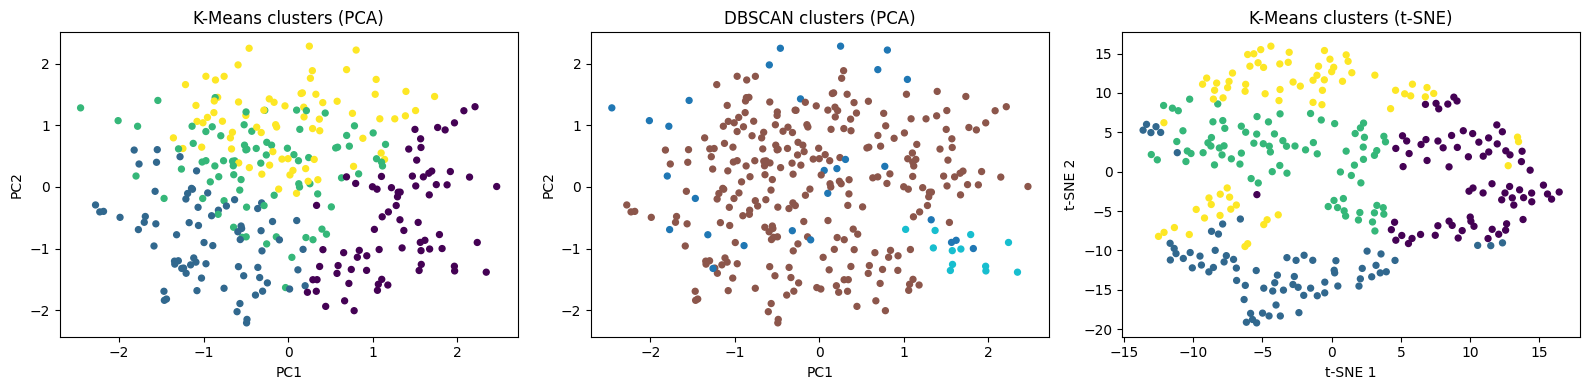

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=df['KMeans_Cluster'], cmap='viridis', s=18)
axes[0].set_title('K-Means clusters (PCA)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=df['DBSCAN_Cluster'], cmap='tab10', s=18)
axes[1].set_title('DBSCAN clusters (PCA)')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=df['KMeans_Cluster'], cmap='viridis', s=18)
axes[2].set_title('K-Means clusters (t-SNE)')
axes[2].set_xlabel('t-SNE 1'); axes[2].set_ylabel('t-SNE 2')
plt.tight_layout()
plt.savefig('customer_clusters.png', dpi=150)
plt.show()


In [ ]:
# 8. Create personas based on average RFM values per K-Means cluster
summary = df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(1)
print('\nAverage RFM by cluster:\n', summary)
# Relative heuristics for this synthetic example; inspect summary for real customers.
median_r, median_f, median_m = X.median()
def persona(row):
    if row['Recency'] <= median_r and row['Frequency'] >= median_f and row['Monetary'] >= median_m:
        return 'Loyal high-value customers'
    if row['Recency'] > median_r and row['Frequency'] >= median_f:
        return 'At-risk former regulars'
    if row['Recency'] <= median_r:
        return 'Recent / growing customers'
    return 'Inactive low-engagement customers'
summary['Persona'] = summary.apply(persona, axis=1)
print('\nCustomer personas:\n', summary)



Average RFM by cluster:
                 Recency  Frequency  Monetary
KMeans_Cluster                              
0                 293.7       11.3    3112.2
1                 121.1        7.6    7060.9
2                 220.4       23.4    7150.8
3                 113.1       22.1    3175.0

Customer personas:
                 Recency  Frequency  Monetary  \
KMeans_Cluster                                 
0                 293.7       11.3    3112.2   
1                 121.1        7.6    7060.9   
2                 220.4       23.4    7150.8   
3                 113.1       22.1    3175.0   

                                          Persona  
KMeans_Cluster                                     
0               Inactive low-engagement customers  
1                      Recent / growing customers  
2                         At-risk former regulars  
3                      Recent / growing customers  


In [ ]:

df['Persona'] = df['KMeans_Cluster'].map(summary['Persona'])
df.to_csv('customer_segments.csv', index=False)
print('\nSaved: rfm_customers.csv, customer_segments.csv, customer_clusters.png')



Saved: rfm_customers.csv, customer_segments.csv, customer_clusters.png
